## Introduction on the Dataset

#### This dataset comprise of three different CSV files namely (Orders, Returns and People) where:

1. **Orders** represent a dataset of sales data for varios accounts in a timespan from 2014 to 2017 and comprise of the 21 columns.

2. **Returns** represent the returned orders and are referenced from the **orders** dataset.

3. **People** are the representatives of the specific regions

## With this dataset we aim to analyze and come up with insights based on the available data to serve as KPIs such as **Total Revenue**, **Total Profit**, **Profit Margin (%)**, **Average Order Value (AOV)** and **Return Rate**.

## In addition to that, we will be looking to answer a few questions based on the available data such as:

* Which product categories are generating the most profit vs. the most losses?

* Is there a specific region with an abnormally high return rate?

* Do higher discounts actually lead to a significant increase in sales quantity?



# Phase 1

In [ ]:
import pandas as pd
import numpy as np
import os

In [ ]:
Data_path = [("/content/drive/MyDrive/Colab Notebooks/EJIM/Datasets/People.csv","people_df"),
             ("/content/drive/MyDrive/Colab Notebooks/EJIM/Datasets/Returns.csv","returns_df"),
             ("/content/drive/MyDrive/Colab Notebooks/EJIM/Datasets/Orders.csv","orders_df")]

# Create a dictionary to store the dataframes
dfs = {}

for file_path, df_name in Data_path:
  dfs[df_name] = pd.read_csv(file_path)



In [ ]:
people_df = dfs['people_df']
returns_df = dfs['returns_df']
orders_df = dfs['orders_df']

## First Look at the Datasets

### Products DF

In [ ]:
orders_df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3.0,CA-2016-138688,6/12/2016,42537.0,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10003,9990.0,CA-2014-110422,1/21/2014,41662.0,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180.0,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3.0,0.20,4.1028
10004,9991.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2.0,0.00,15.6332
10005,9992.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2.0,0.20,19.3932
10006,9993.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200


In [ ]:
print(orders_df.info())
print(f"-----------------------------------------")
print(f"Missing values\n: {orders_df.isna().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10008 entries, 0 to 10007
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9998 non-null   float64
 1   Order ID       9998 non-null   object 
 2   Order Date     9998 non-null   object 
 3   Ship Date      9998 non-null   float64
 4   Ship Mode      9998 non-null   object 
 5   Customer ID    9998 non-null   object 
 6   Customer Name  9998 non-null   object 
 7   Segment        9998 non-null   object 
 8   Country        9998 non-null   object 
 9   City           9998 non-null   object 
 10  State          9998 non-null   object 
 11  Postal Code    9998 non-null   float64
 12  Region         9998 non-null   object 
 13  Product ID     9998 non-null   object 
 14  Category       9998 non-null   object 
 15  Sub-Category   9998 non-null   object 
 16  Product Name   9998 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

In [ ]:
# Duplicate rows check and drop them accordingly
orders_df.duplicated().sum()

np.int64(13)

In [ ]:
# Looking at the way the missing values exist we will naturally drop them
orders_df[orders_df.isna()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
orders_df.drop_duplicates(inplace=True)
orders_df.reset_index(drop=True, inplace=True)

In [ ]:
orders_df.dropna(inplace=True)
orders_df.reset_index(drop=True, inplace=True)
orders_df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3.0,CA-2016-138688,6/12/2016,42537.0,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9965,9990.0,CA-2014-110422,1/21/2014,41662.0,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180.0,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3.0,0.20,4.1028
9966,9991.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2.0,0.00,15.6332
9967,9992.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2.0,0.20,19.3932
9968,9993.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200


In [ ]:
# Get summary statistics from this dataframe

orders_df[['Sales','Quantity','Discount',"Profit"] ].describe()

,Sales,Quantity,Discount,Profit
count,9970.000000,9970.000000,9970.000000,9970.000000
mean,229.759844,3.788766,0.156539,28.575904
std,623.108657,2.223565,0.206569,234.439874
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.256000,2.000000,0.000000,1.724800
50%,54.490000,3.000000,0.200000,8.652800
75%,209.940000,5.000000,0.200000,29.362500
max,22638.480000,14.000000,0.800000,8399.976000


### Returns DF

In [ ]:
returns_df

,Returned,Order ID
0,Yes,CA-2017-153822
1,Yes,CA-2017-129707
2,Yes,CA-2014-152345
3,Yes,CA-2015-156440
4,Yes,US-2017-155999
...,...,...
291,Yes,CA-2015-101910
292,Yes,CA-2017-156958
293,Yes,CA-2016-105585
294,Yes,CA-2016-148796


## Merging Tables and dealing with Discrepancies

In [ ]:
# First we check for null and duplicated values in the returns dataset

print(f"NA check:\n\n{returns_df.isna().sum()}")
print(f"\nDuplicate check:\t {returns_df.duplicated().sum()}")

NA check:

Returned    0
Order ID    0
dtype: int64

Duplicate check:	 0


### Merging the **orders** and **returns** dfs on the *Order_ID*

In [ ]:
R1_df = pd.merge(orders_df, returns_df, on='Order ID', how='left')
R1_df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Returned
0,1.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,NaN
1,2.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,NaN
2,3.0,CA-2016-138688,6/12/2016,42537.0,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,NaN
3,4.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,NaN
4,5.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9965,9990.0,CA-2014-110422,1/21/2014,41662.0,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3.0,0.20,4.1028,NaN
9966,9991.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2.0,0.00,15.6332,Yes
9967,9992.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2.0,0.20,19.3932,Yes
9968,9993.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200,Yes


* Looking at the results of the join operation, I would assume that values with NaN is translated and not returned. Therefore I will replace it with "No".
* Also while looking further we notice that the region names are inconsistent, so we solve this as well.

In [ ]:
R1_df["Returned"].value_counts()

,count
Returned,
Yes,800


In [ ]:
R1_df["Returned"].replace([np.nan], "No", inplace=True)

/tmp/ipython-input-2240487839.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  R1_df["Returned"].replace([np.nan], "No", inplace=True)


In [ ]:
R1_df["Returned"].value_counts()

,count
Returned,
No,9170
Yes,800


### Merging the latest merged df **R1** with the **people** df on the region value

In [ ]:
# Looking at the regions column in the orders df, we see that the values are inconsistent
orders_df['Region'].value_counts()

,count
Region,
West,3197
East,2839
Central,2311
South,1619
EST,2
WSR,1
west,1


In [ ]:
people_df['Region'].value_counts()

,count
Region,
West,1
East,1
Central,1
South,1


In [ ]:
# So we solve this inconsistency in here

people_df['Region'] = people_df['Region'].str.lower()
R1_df['Region'] = R1_df['Region'].str.lower()
R1_df.replace('est',"east",inplace=True)
R1_df.replace('wsr',"west",inplace=True)

In [ ]:
# Then we check again

R1_df['Region'].value_counts()

,count
Region,
west,3199
east,2841
central,2311
south,1619


In [ ]:
R2_df = pd.merge(R1_df, people_df, on='Region', how='left')

In [ ]:
R2_df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Returned,Person
0,1.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,No,Cassandra Brandow
1,2.0,CA-2016-152156,11/8/2016,42685.0,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,No,Cassandra Brandow
2,3.0,CA-2016-138688,6/12/2016,42537.0,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,No,Anna Andreadi
3,4.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,No,Cassandra Brandow
4,5.0,US-2015-108966,10/11/2015,42295.0,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,No,Cassandra Brandow
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9965,9990.0,CA-2014-110422,1/21/2014,41662.0,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3.0,0.20,4.1028,No,Cassandra Brandow
9966,9991.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2.0,0.00,15.6332,Yes,Anna Andreadi
9967,9992.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2.0,0.20,19.3932,Yes,Anna Andreadi
9968,9993.0,CA-2017-121258,2/26/2017,42797.0,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4.0,0.00,13.3200,Yes,Anna Andreadi


In [ ]:
# Final check for null values

R2_df.isna().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


NaN solved :)

# Phase 2

### In this phase we will be performing time series analysis on weekly, monthly, quarterly and yearly basis

*   **Sales Analysis (Sum)**: Visualized the total Sales on a weekly, monthly, quarterly, and yearly basis.
*   **Profit Analysis (Sum)**: Visualized the total profit on a weekly, monthly, quarterly, and yearly basis.
*   **Quantity Analysis (Sum)**: Visualized the total quantity sold on a weekly, monthly, quarterly, and yearly basis.
*   **Discount Analysis (Mean)**: Visualized the average discount applied (converted to percentage) on a weekly, monthly, quarterly, and yearly basis.



/tmp/ipython-input-2884406439.py:9: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly = df[column].resample('Q').apply(agg_func)
/tmp/ipython-input-2884406439.py:10: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly = df[column].resample('A').apply(agg_func)


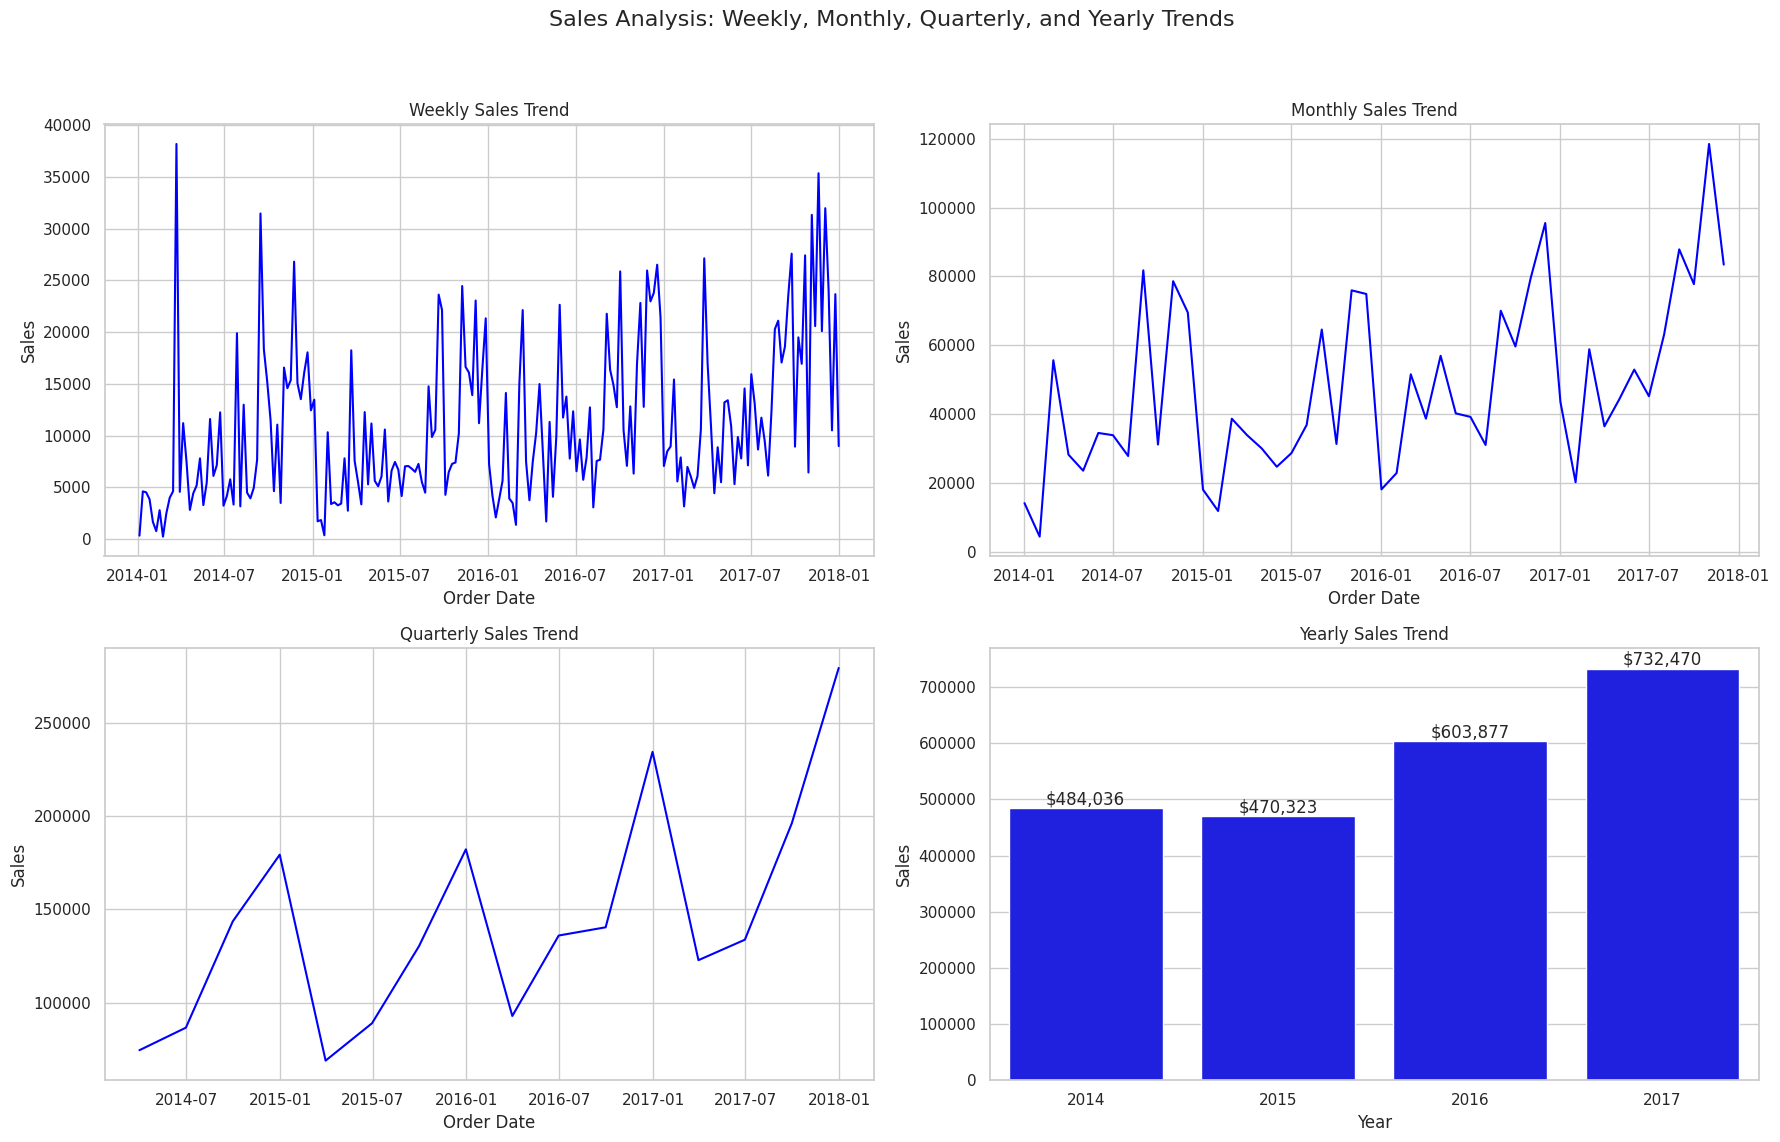

/tmp/ipython-input-2884406439.py:9: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly = df[column].resample('Q').apply(agg_func)
/tmp/ipython-input-2884406439.py:10: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly = df[column].resample('A').apply(agg_func)


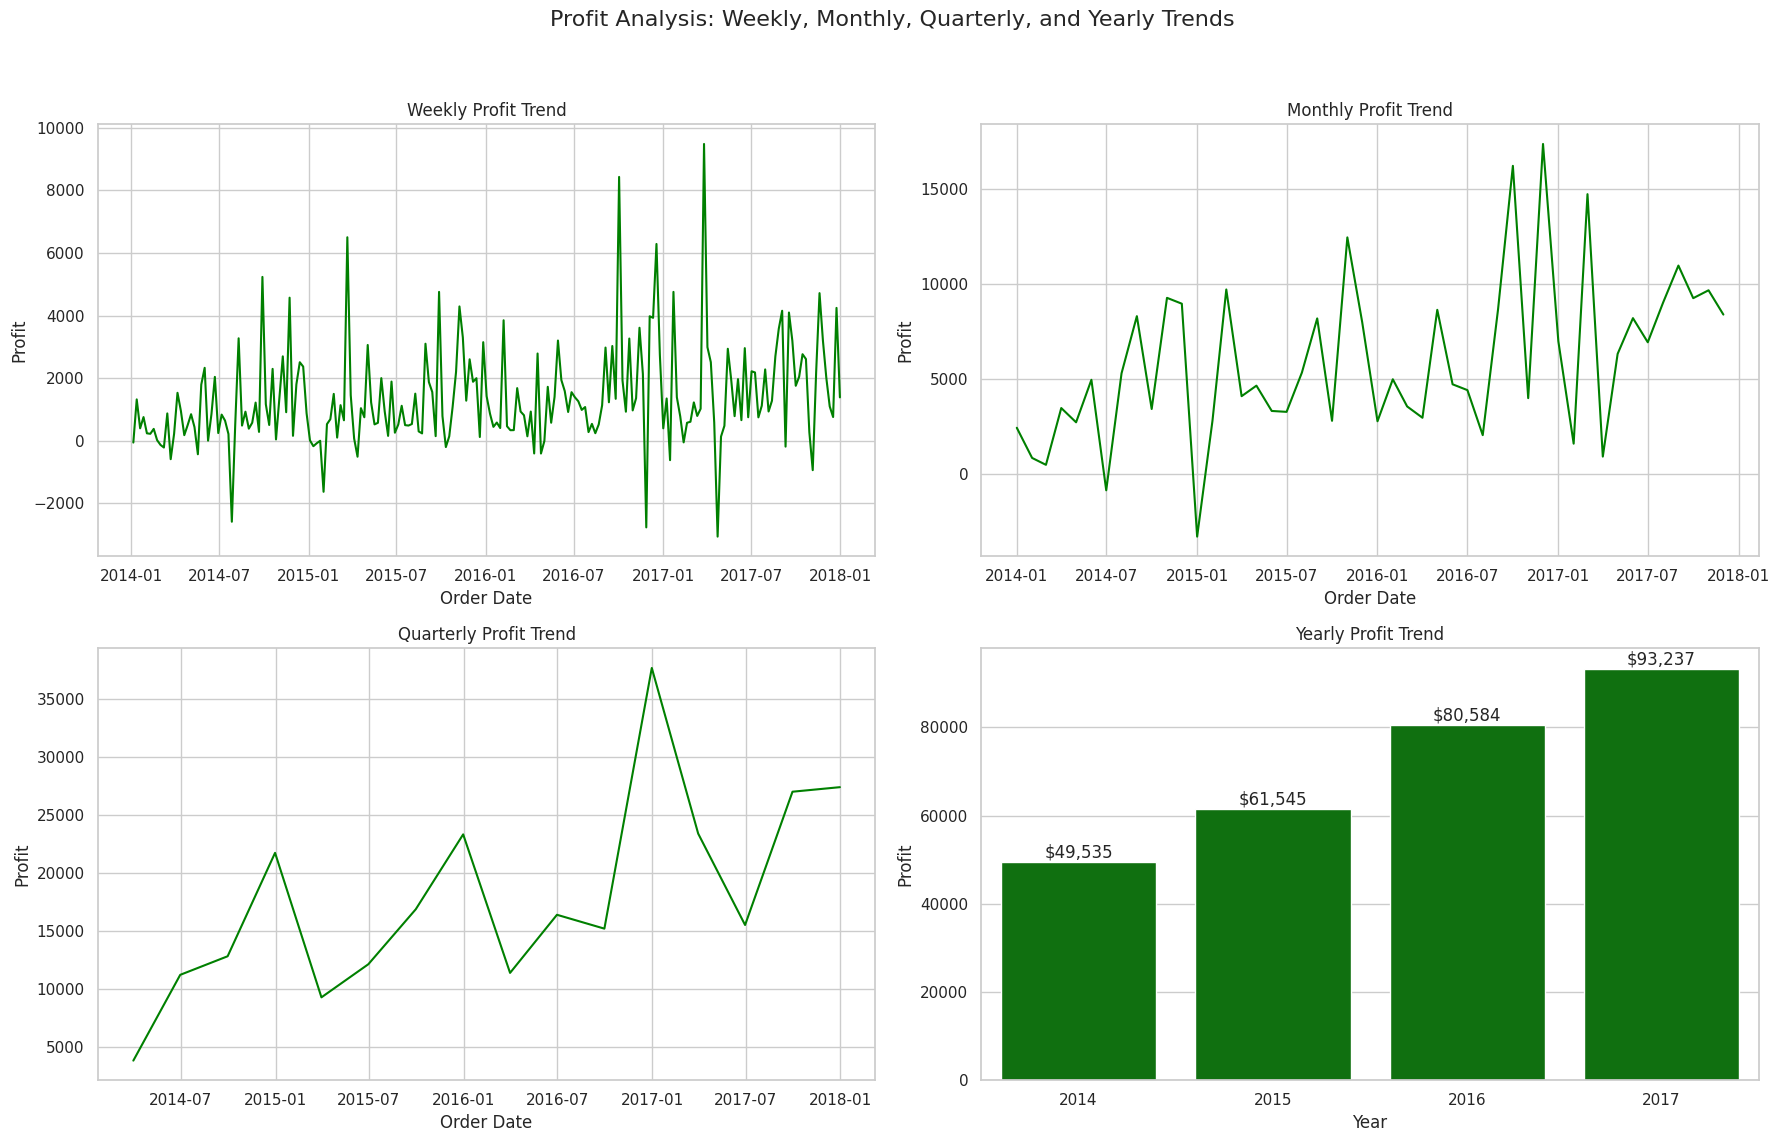

/tmp/ipython-input-2884406439.py:9: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly = df[column].resample('Q').apply(agg_func)
/tmp/ipython-input-2884406439.py:10: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly = df[column].resample('A').apply(agg_func)


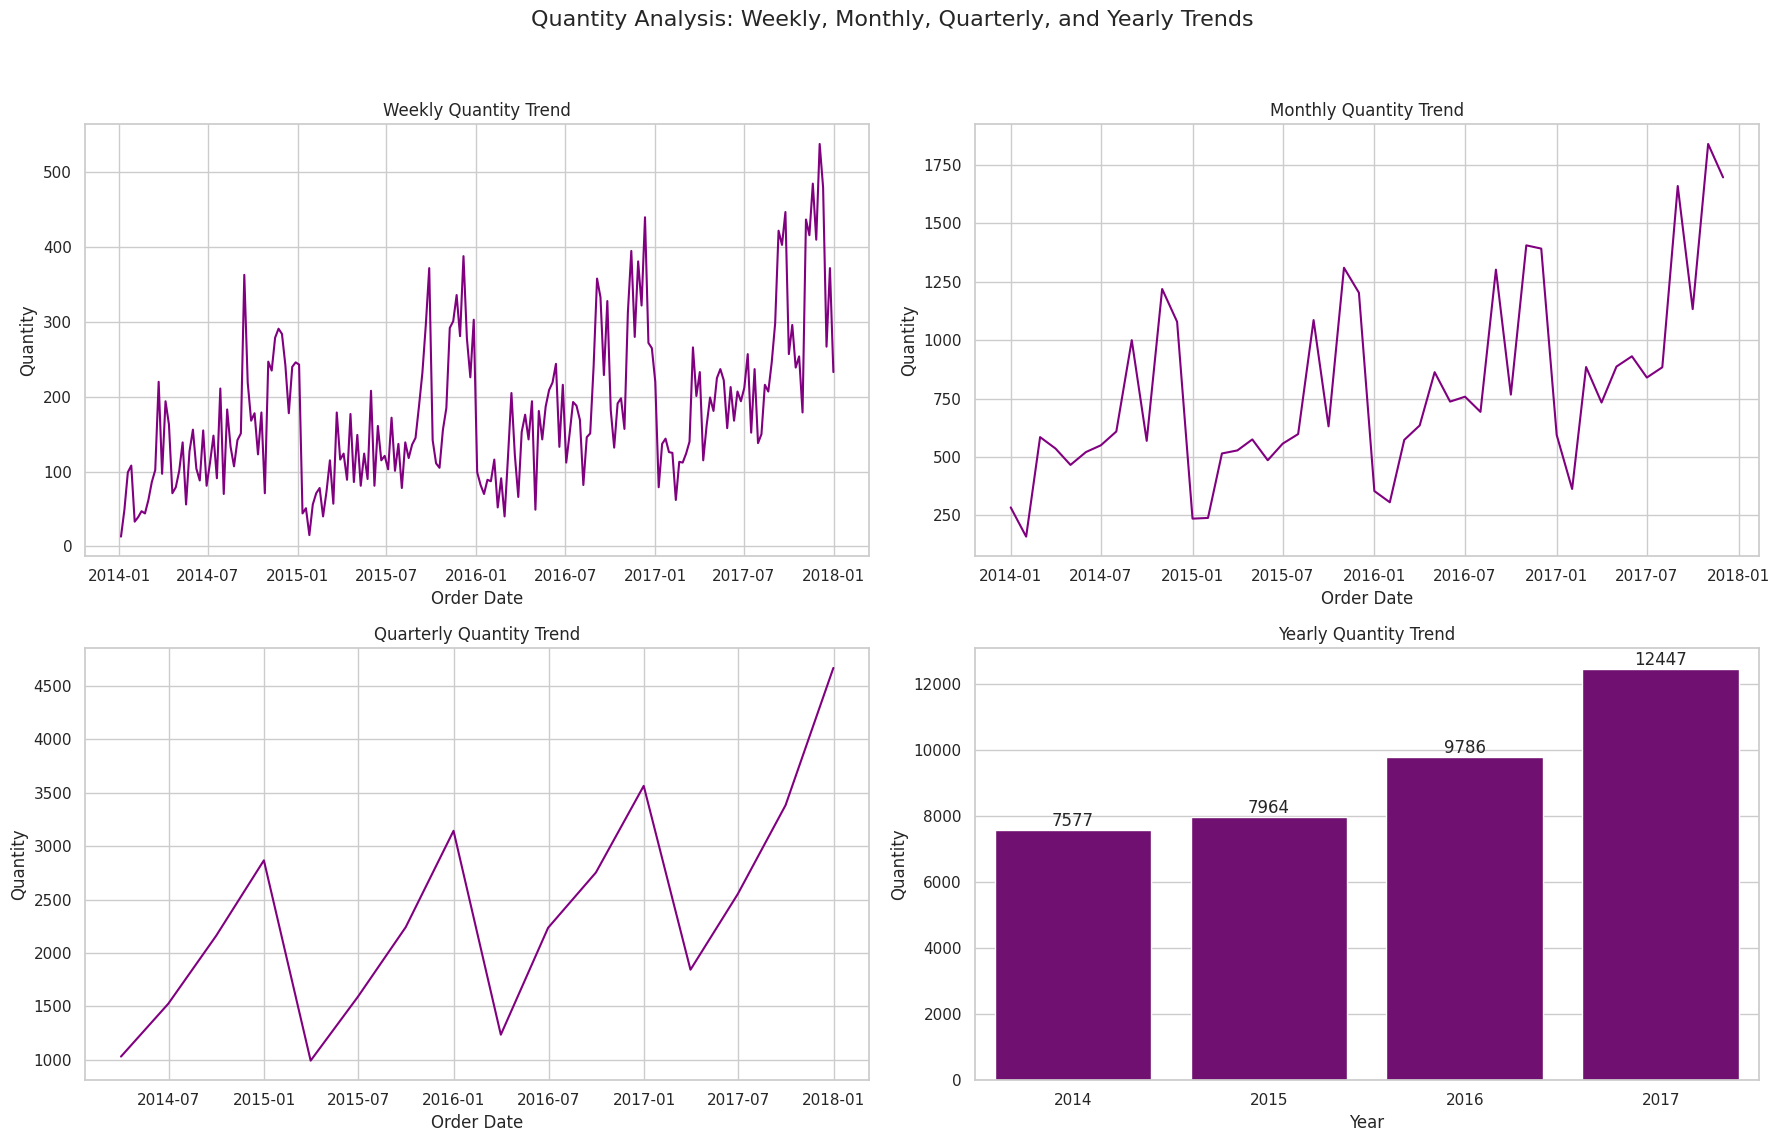

/tmp/ipython-input-2884406439.py:9: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly = df[column].resample('Q').apply(agg_func)
/tmp/ipython-input-2884406439.py:10: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly = df[column].resample('A').apply(agg_func)


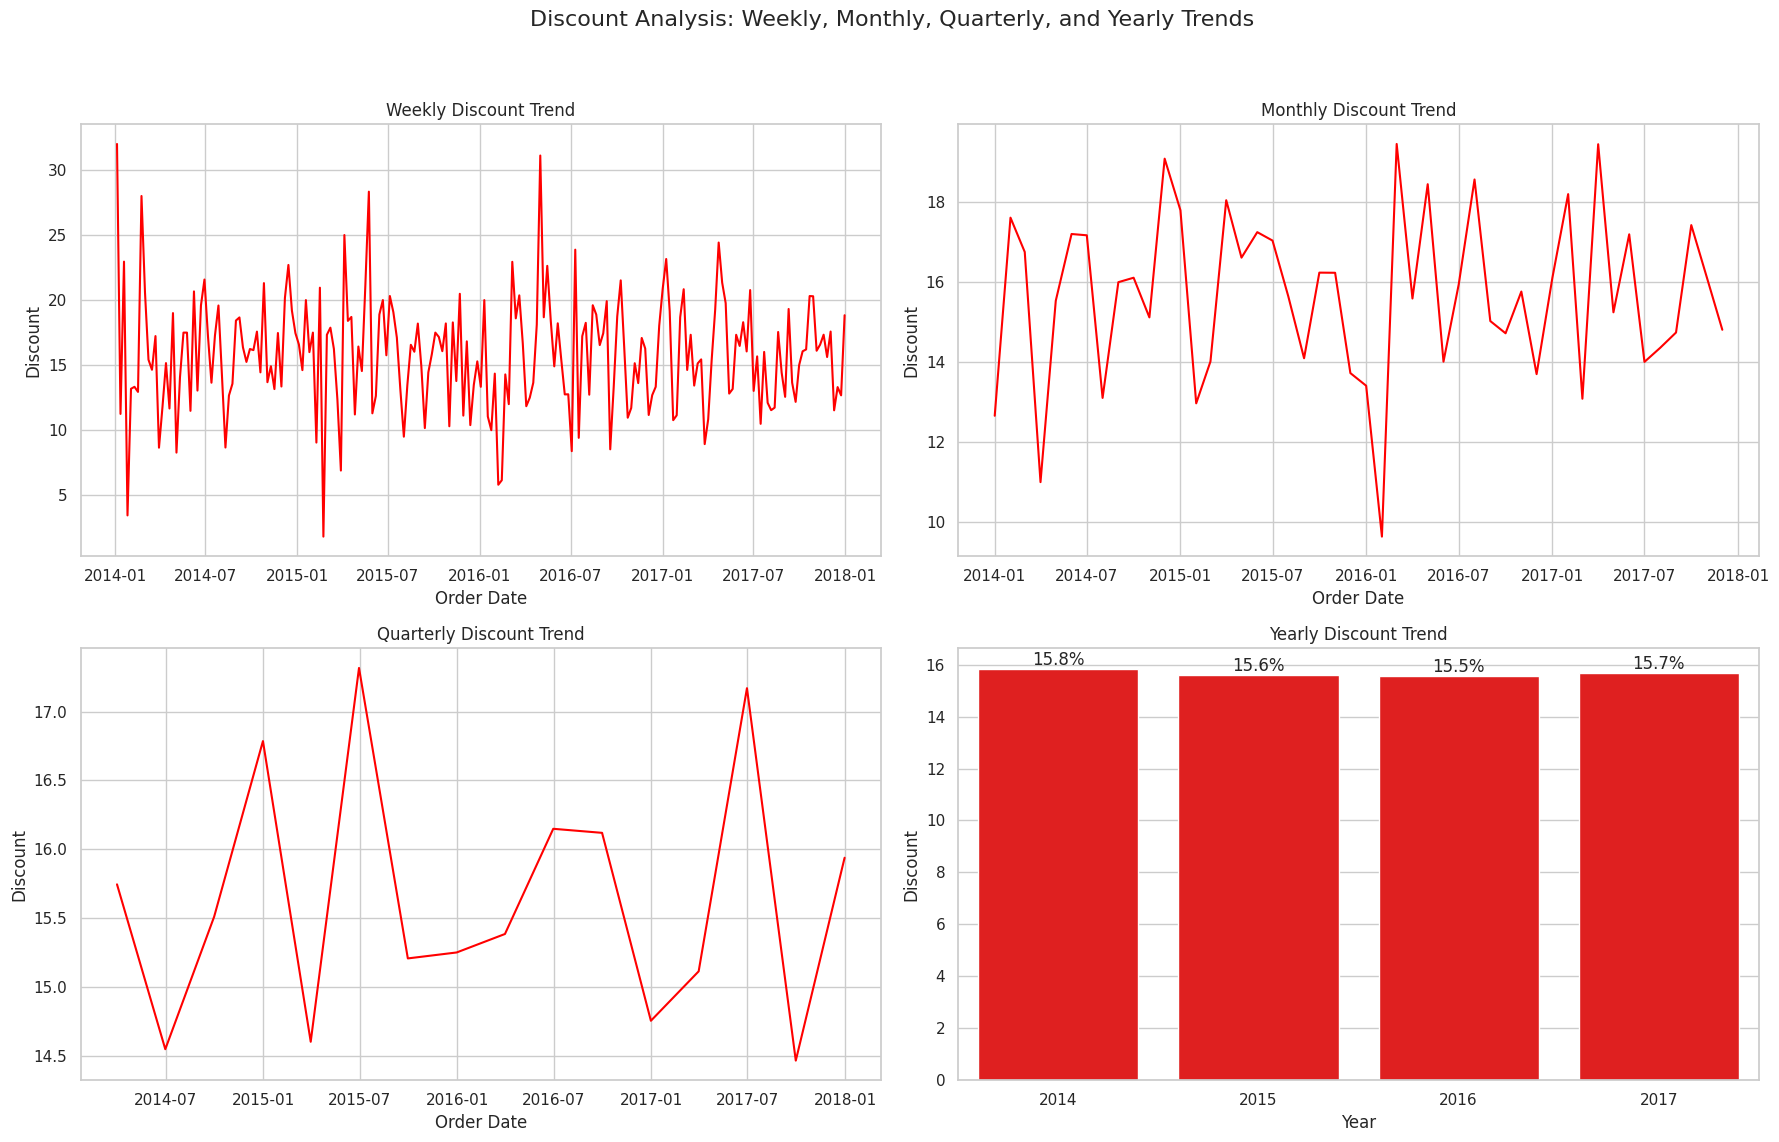

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_time_series(df, column, agg_func, title_prefix, color_theme):

    weekly = df[column].resample('W').apply(agg_func)
    monthly = df[column].resample('MS').apply(agg_func)
    quarterly = df[column].resample('Q').apply(agg_func)
    yearly = df[column].resample('A').apply(agg_func)

    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle(f'{title_prefix} Analysis: Weekly, Monthly, Quarterly, and Yearly Trends', fontsize=16)

    # Weekly Trend
    sns.lineplot(x=weekly.index, y=weekly.values, ax=axes[0, 0], color=color_theme)
    axes[0, 0].set_title(f'Weekly {title_prefix} Trend')
    axes[0, 0].set_ylabel(title_prefix)

    # Monthly Trend
    sns.lineplot(x=monthly.index, y=monthly.values, ax=axes[0, 1], color=color_theme)
    axes[0, 1].set_title(f'Monthly {title_prefix} Trend')
    axes[0, 1].set_ylabel(title_prefix)

    # Quarterly Trend
    sns.lineplot(x=quarterly.index, y=quarterly.values, ax=axes[1, 0], color=color_theme)
    axes[1, 0].set_title(f'Quarterly {title_prefix} Trend')
    axes[1, 0].set_ylabel(title_prefix)

    # Yearly Trend (Bar Chart)
    sns.barplot(x=yearly.index.year, y=yearly.values, ax=axes[1, 1], color=color_theme)
    axes[1, 1].set_title(f'Yearly {title_prefix} Trend')
    axes[1, 1].set_ylabel(title_prefix)
    axes[1, 1].set_xlabel('Year')


    for container in axes[1, 1].containers:

        if title_prefix == 'Discount':
            axes[1, 1].bar_label(container, fmt='%.1f%%')
        elif title_prefix == 'Quantity':
            axes[1, 1].bar_label(container, fmt='%.0f')
        else:
            axes[1, 1].bar_label(container, fmt='${:,.0f}')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


R2_df['Order Date'] = pd.to_datetime(R2_df['Order Date'], errors='coerce')
time_df = R2_df.set_index('Order Date')


# 1. Sales Analysis (Sum)

plot_time_series(time_df, 'Sales', 'sum', 'Sales', 'blue')

# 1. Profit Analysis (Sum)

plot_time_series(time_df, 'Profit', 'sum', 'Profit', 'green')


# 2. Quantity Analysis (Sum)

plot_time_series(time_df, 'Quantity', 'sum', 'Quantity', 'purple')

# 3. Discount Analysis (Mean)

time_df_pct = time_df.copy()
time_df_pct['Discount'] = time_df_pct['Discount'] * 100
plot_time_series(time_df_pct, 'Discount', 'mean', 'Discount', 'red')

*   **Profit Margin**: Calculated as `(Sum of Profit / Sum of Sales) * 100`.
*   **Average Order Value (AOV)**: Calculated as `Sum of Sales / Count of Unique Order IDs`.
*   **Return Rate**: Calculated as `(Count of Unique Returned Orders / Count of Total Unique Orders) * 100`.

Each of these KPIs was analyzed and plotted on weekly, monthly, quarterly, and yearly bases, providing deep insights into the business's financial health and operational efficiency.

 We investigated the relationship between discount levels and the average quantity of items sold. A line plot, complemented by a scatter plot, was used to visualize how the average quantity per order changes with different discount percentages. This helps understand if higher discounts effectively lead to a significant increase in sales volume.

/tmp/ipython-input-312420650.py:9: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  sales = df['Sales'].resample(freq).sum()
/tmp/ipython-input-312420650.py:10: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  profit = df['Profit'].resample(freq).sum()
/tmp/ipython-input-312420650.py:9: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  sales = df['Sales'].resample(freq).sum()
/tmp/ipython-input-312420650.py:10: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  profit = df['Profit'].resample(freq).sum()


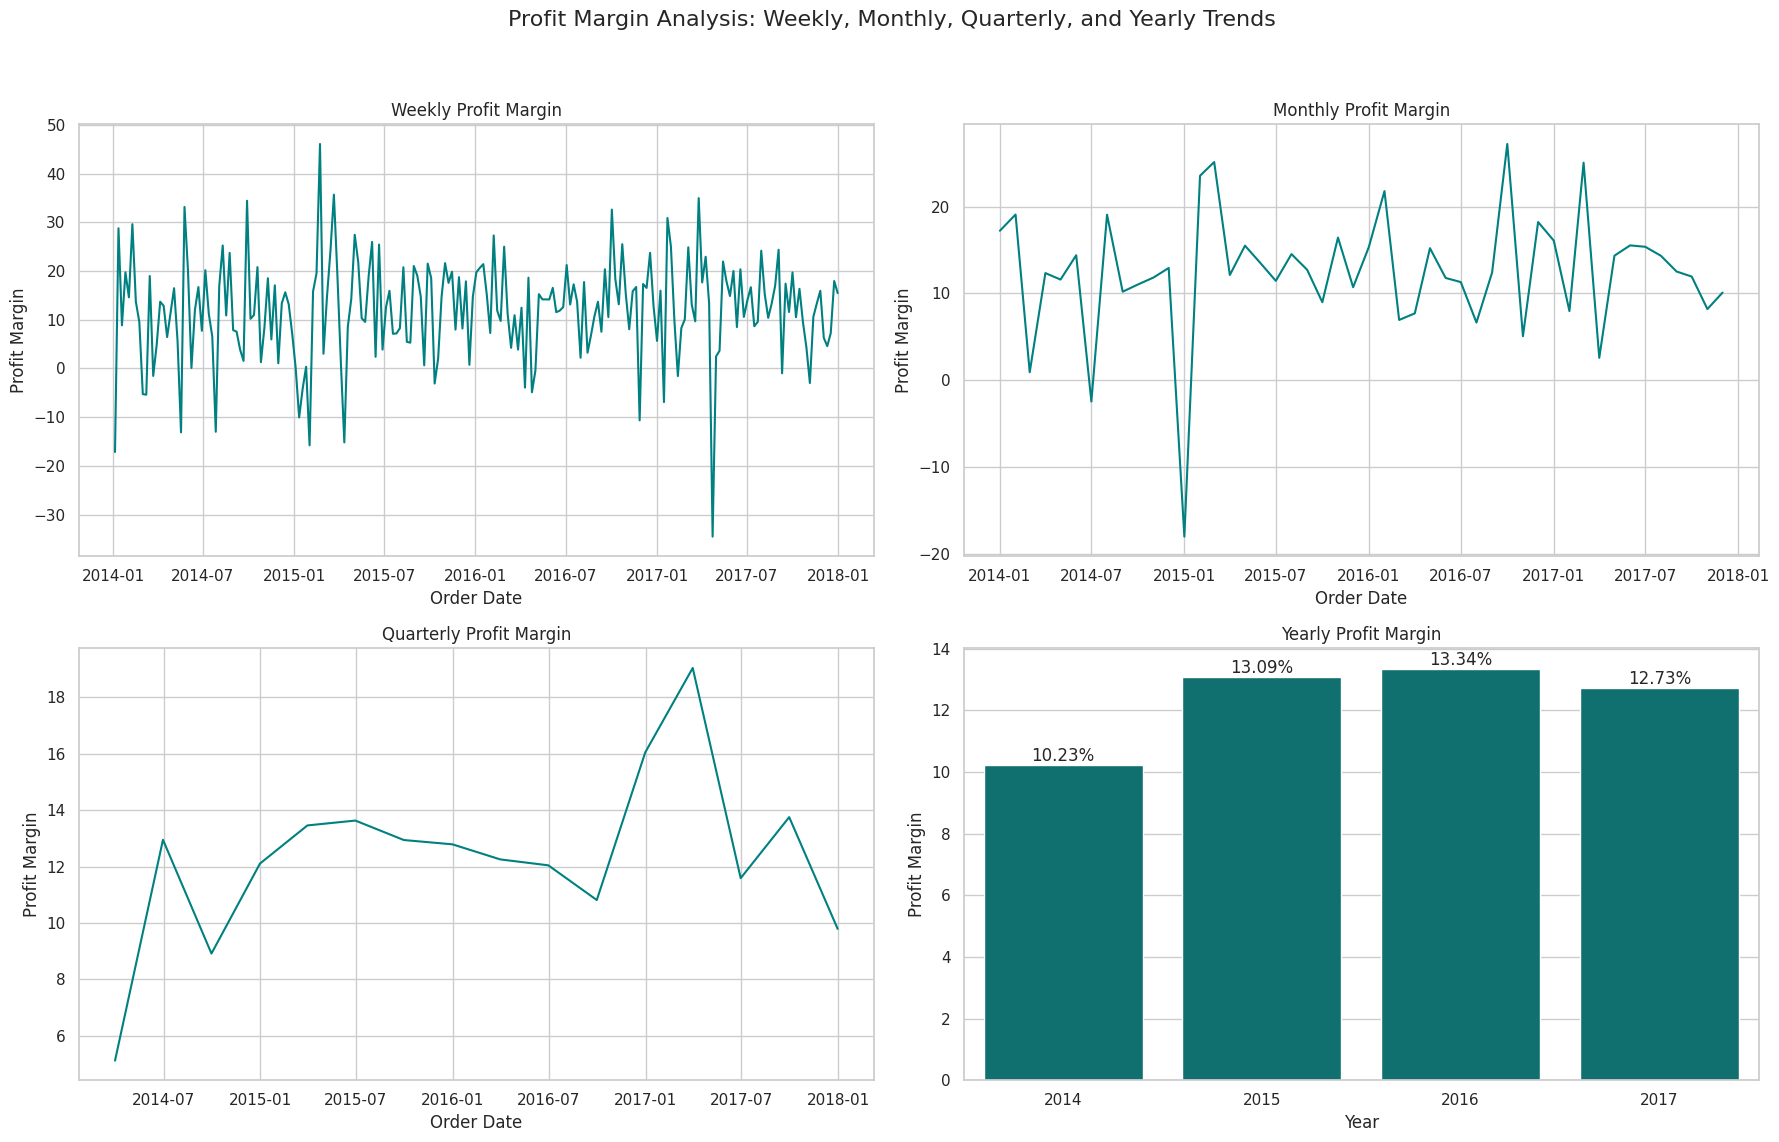

/tmp/ipython-input-312420650.py:15: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  sales = df['Sales'].resample(freq).sum()
/tmp/ipython-input-312420650.py:16: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  orders = df['Order ID'].resample(freq).nunique()
/tmp/ipython-input-312420650.py:15: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  sales = df['Sales'].resample(freq).sum()
/tmp/ipython-input-312420650.py:16: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  orders = df['Order ID'].resample(freq).nunique()


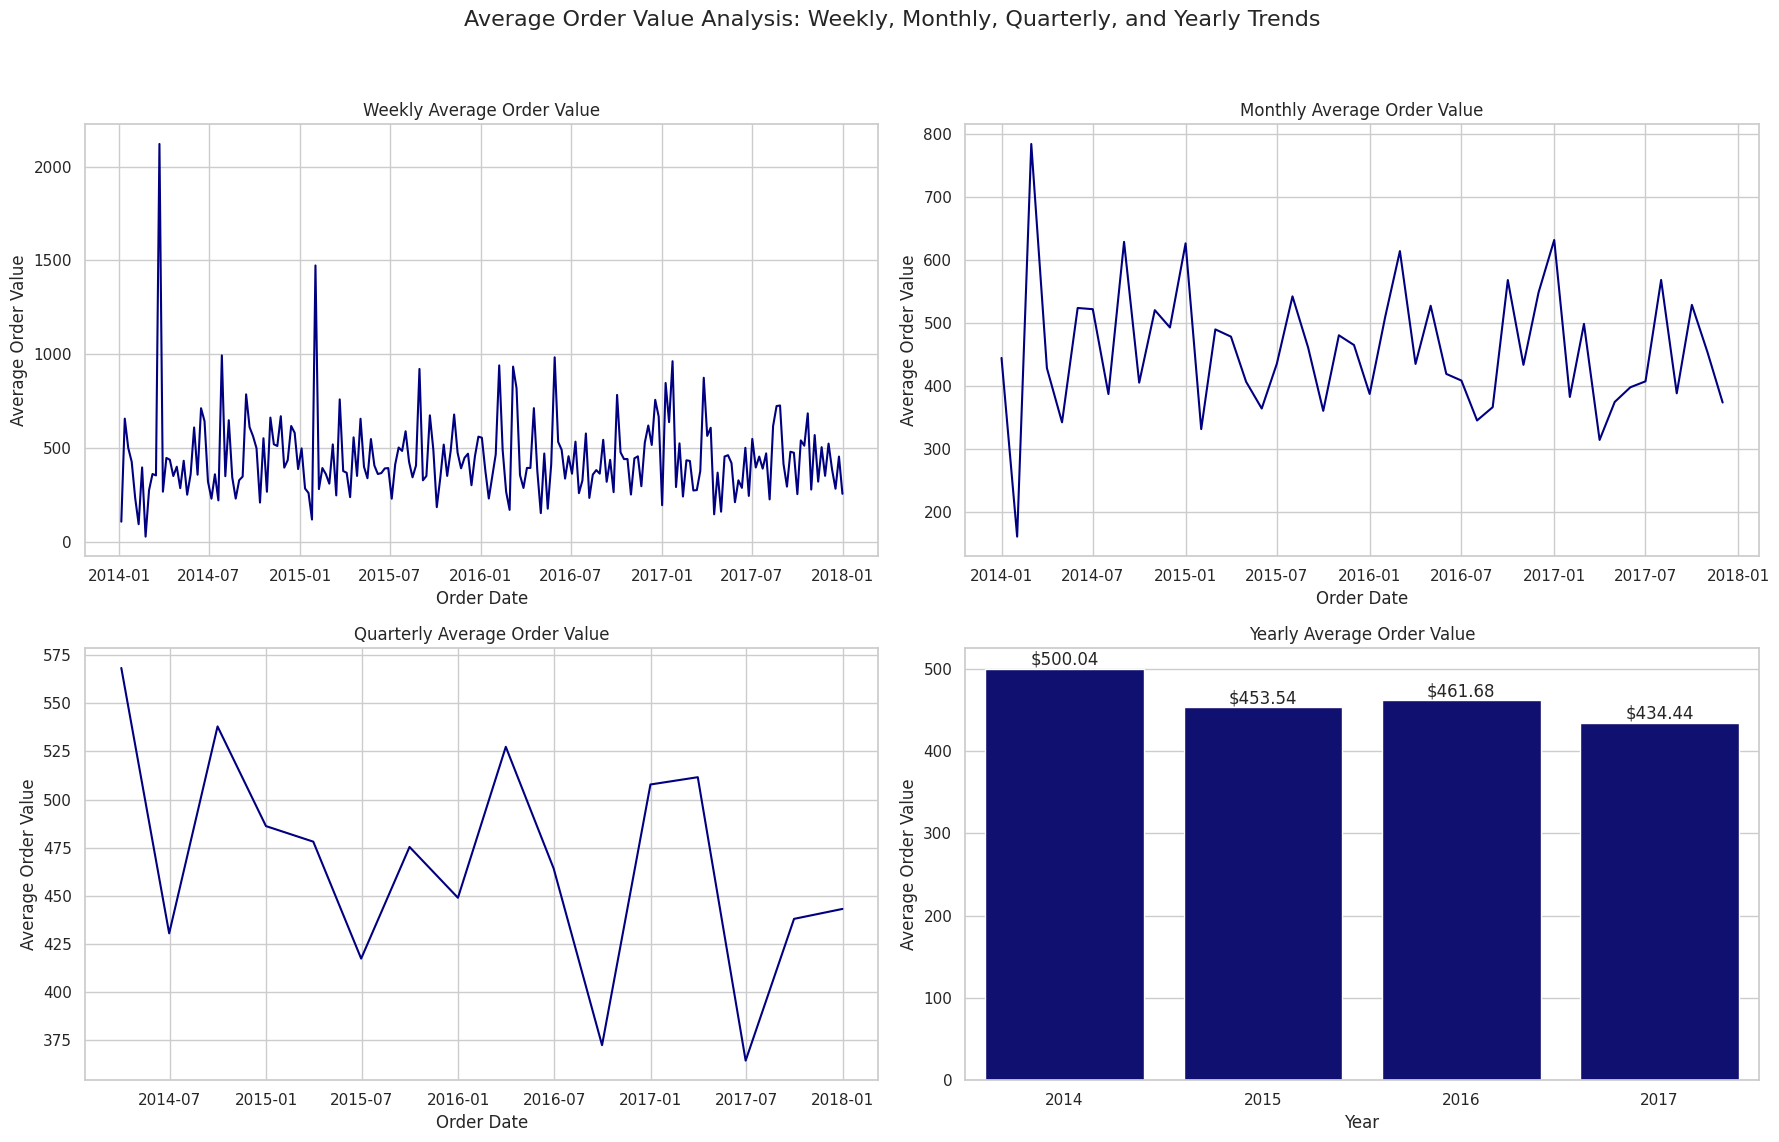

/tmp/ipython-input-312420650.py:21: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  total_orders = df['Order ID'].resample(freq).nunique()
/tmp/ipython-input-312420650.py:23: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  returned_orders = df[df['Returned'] == 'Yes']['Order ID'].resample(freq).nunique()
/tmp/ipython-input-312420650.py:21: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  total_orders = df['Order ID'].resample(freq).nunique()
/tmp/ipython-input-312420650.py:23: FutureWarning: 'A' is deprecated and will be removed in a future version, please use 'YE' instead.
  returned_orders = df[df['Returned'] == 'Yes']['Order ID'].resample(freq).nunique()


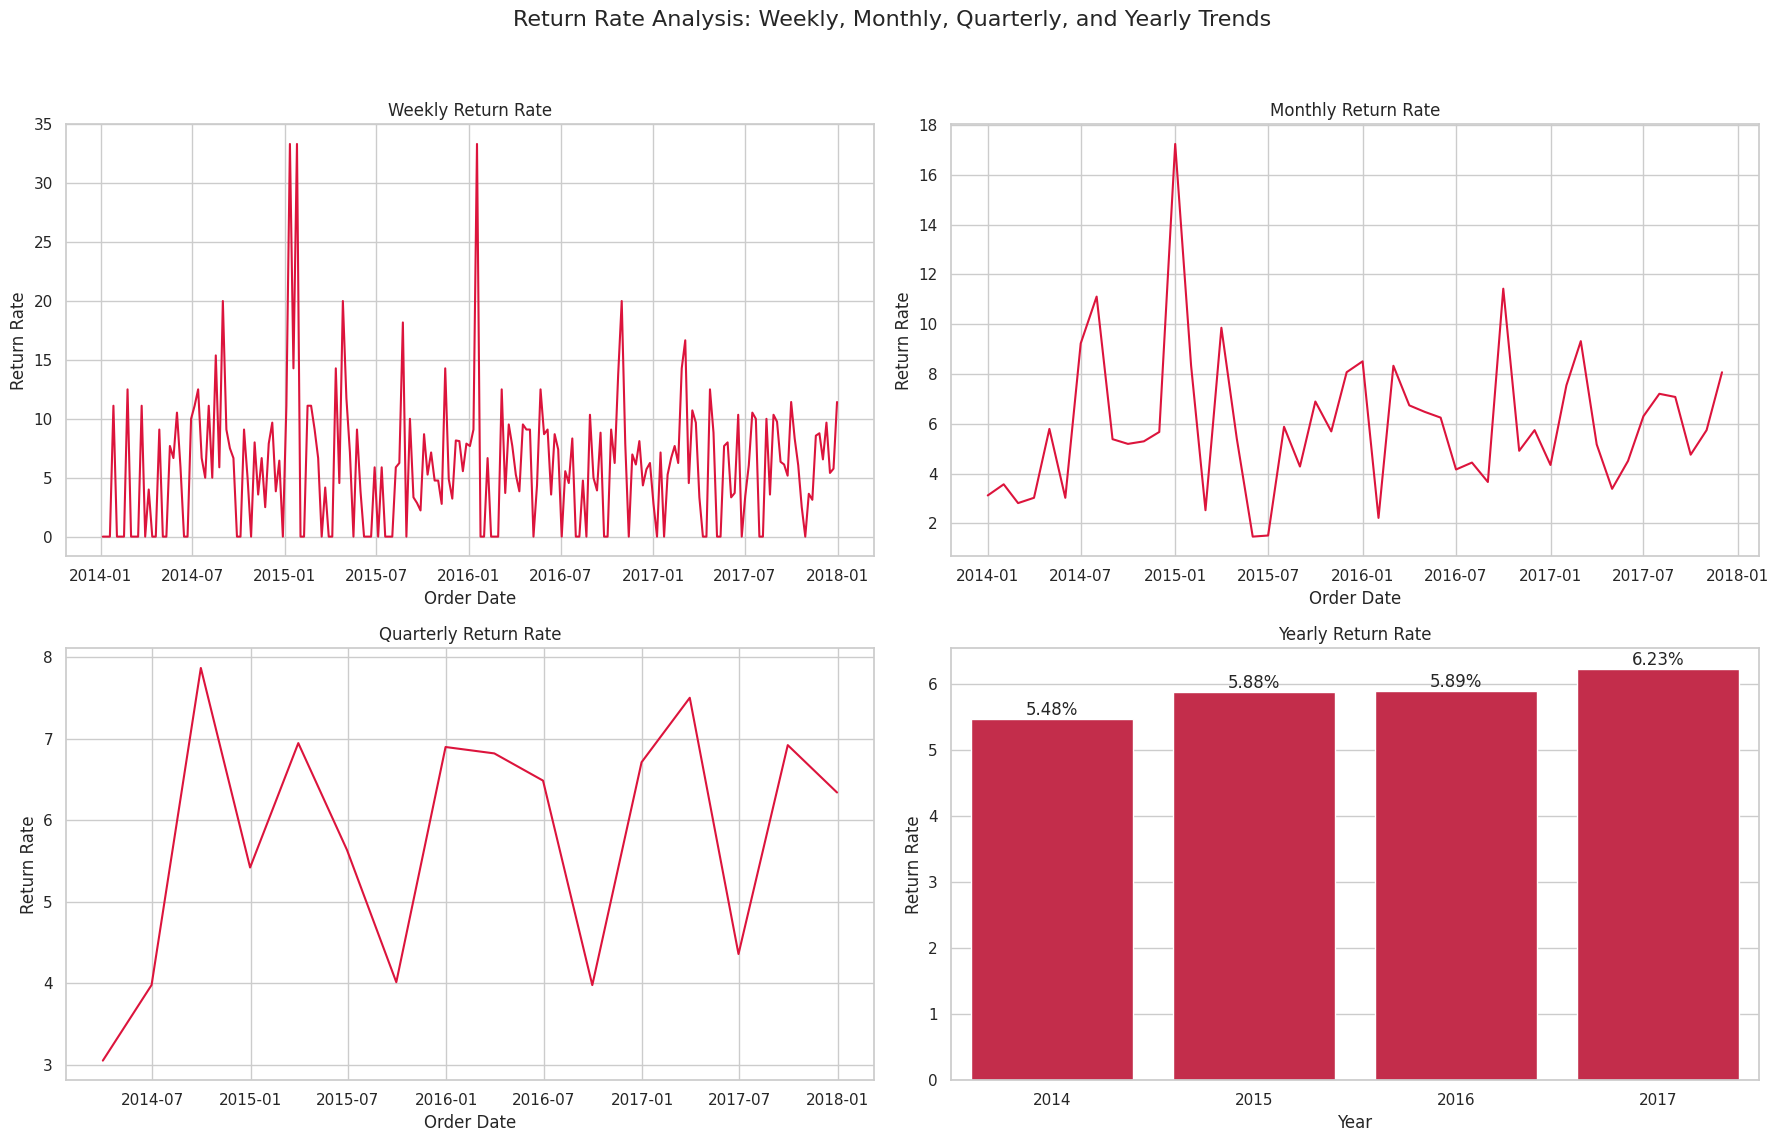

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


def get_kpi_series(df, freq, kpi_name):
    if kpi_name == 'Profit Margin':
        # Formula: (Sum of Profit / Sum of Sales) * 100
        sales = df['Sales'].resample(freq).sum()
        profit = df['Profit'].resample(freq).sum()
        return (profit / sales.replace(0, np.nan)) * 100

    elif kpi_name == 'Average Order Value':
        # Formula: Sum of Sales / Count of Unique Order IDs
        sales = df['Sales'].resample(freq).sum()
        orders = df['Order ID'].resample(freq).nunique()
        return sales / orders.replace(0, np.nan)

    elif kpi_name == 'Return Rate':
        # Formula: (Count of Unique Returned Orders / Count of Total Unique Orders) * 100
        total_orders = df['Order ID'].resample(freq).nunique()

        returned_orders = df[df['Returned'] == 'Yes']['Order ID'].resample(freq).nunique()
        returned_orders = returned_orders.reindex(total_orders.index, fill_value=0)
        return (returned_orders / total_orders.replace(0, np.nan)) * 100


def plot_complex_kpi(df, kpi_name, color_theme):

    weekly = get_kpi_series(df, 'W', kpi_name)
    monthly = get_kpi_series(df, 'MS', kpi_name)
    quarterly = get_kpi_series(df, 'Q', kpi_name)
    yearly = get_kpi_series(df, 'A', kpi_name)


    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle(f'{kpi_name} Analysis: Weekly, Monthly, Quarterly, and Yearly Trends', fontsize=16)

    # 1. Weekly
    sns.lineplot(x=weekly.index, y=weekly.values, ax=axes[0, 0], color=color_theme)
    axes[0, 0].set_title(f'Weekly {kpi_name}')
    axes[0, 0].set_ylabel(kpi_name)

    # 2. Monthly
    sns.lineplot(x=monthly.index, y=monthly.values, ax=axes[0, 1], color=color_theme)
    axes[0, 1].set_title(f'Monthly {kpi_name}')
    axes[0, 1].set_ylabel(kpi_name)

    # 3. Quarterly
    sns.lineplot(x=quarterly.index, y=quarterly.values, ax=axes[1, 0], color=color_theme)
    axes[1, 0].set_title(f'Quarterly {kpi_name}')
    axes[1, 0].set_ylabel(kpi_name)

    # 4. Yearly (Bar Chart)
    sns.barplot(x=yearly.index.year, y=yearly.values, ax=axes[1, 1], color=color_theme)
    axes[1, 1].set_title(f'Yearly {kpi_name}')
    axes[1, 1].set_ylabel(kpi_name)
    axes[1, 1].set_xlabel('Year')


    for container in axes[1, 1].containers:
        if kpi_name == 'Average Order Value':
            axes[1, 1].bar_label(container, fmt='$%.2f')
        else:
            axes[1, 1].bar_label(container, fmt='%.2f%%')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


if 'time_df' not in locals():
    R2_df['Order Date'] = pd.to_datetime(R2_df['Order Date'], errors='coerce')
    time_df = R2_df.set_index('Order Date')

# 1. Profit Margin
plot_complex_kpi(time_df, 'Profit Margin', 'teal')

# 2. Average Order Value
plot_complex_kpi(time_df, 'Average Order Value', 'navy')

# 3. Return Rate
plot_complex_kpi(time_df, 'Return Rate', 'crimson')

We also analyzed which product categories and sub-categories contribute the most to profit or loss. A bar plot was generated to display the total profit by each sub-category, categorized by their main category. A vertical line at zero profit clearly distinguished profitable sub-categories from those incurring losses.

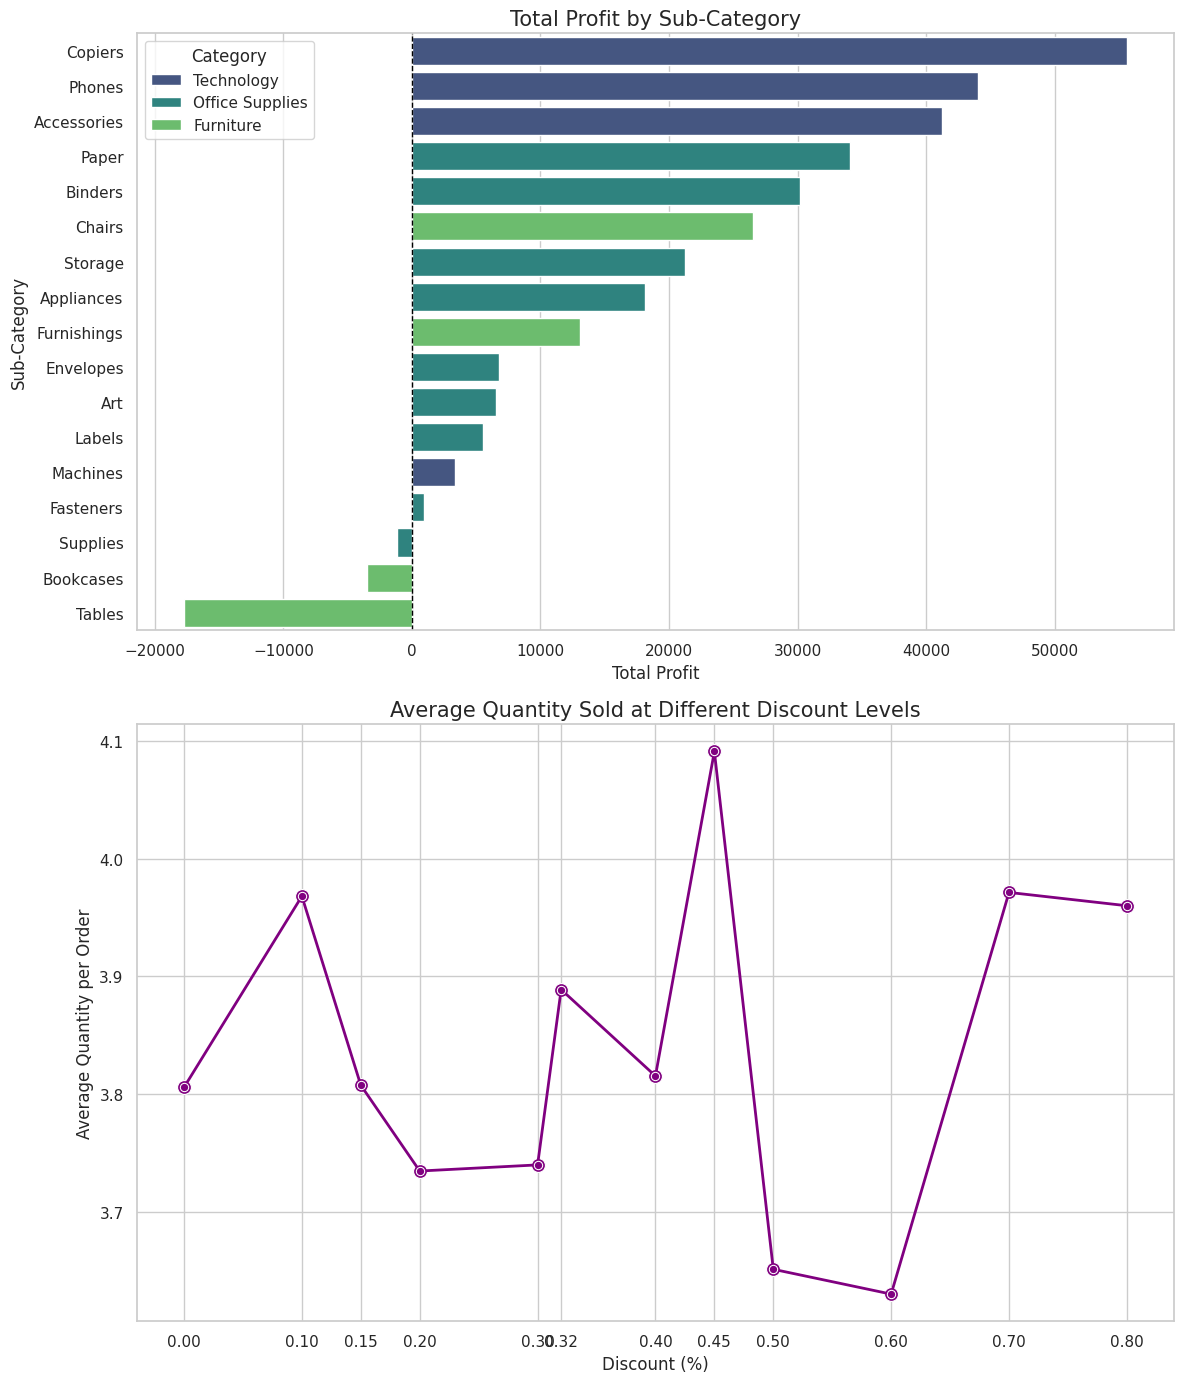

In [ ]:
sns.set(style="whitegrid")

fig, axes = plt.subplots(2, 1, figsize=(12, 14))


subcat_profit = R2_df.groupby(['Category', 'Sub-Category'])['Profit'].sum().reset_index()
subcat_profit = subcat_profit.sort_values(by='Profit', ascending=False)

sns.barplot(
    data=subcat_profit,
    y='Sub-Category',
    x='Profit',
    hue='Category',
    dodge=False,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Total Profit by Sub-Category', fontsize=15)
axes[0].set_xlabel('Total Profit')
axes[0].set_ylabel('Sub-Category')
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=1) # Line at 0 to show losses clearly


avg_qty_discount = R2_df.groupby('Discount')['Quantity'].mean().reset_index()

sns.lineplot(
    data=avg_qty_discount,
    x='Discount',
    y='Quantity',
    marker='o',
    color='purple',
    linewidth=2,
    ax=axes[1]
)
# Optional: Add a scatter plot on top to emphasize the points
sns.scatterplot(
    data=avg_qty_discount,
    x='Discount',
    y='Quantity',
    s=100,
    color='purple',
    ax=axes[1]
)

axes[1].set_title('Average Quantity Sold at Different Discount Levels', fontsize=15)
axes[1].set_xlabel('Discount (%)')
axes[1].set_ylabel('Average Quantity per Order')
axes[1].set_xticks(avg_qty_discount['Discount'].unique()) # Ensure all discount levels are shown

# Adjust layout and show
plt.tight_layout()
plt.show()